# Mongolia provincial livestock mortality and 2020 environmental indicators

Reconstruction from real 2021 livestock losses and 2020 livestock populations in the original archived workbook, plus the MODIS, NASA–USDA SMAP and FLDAS results computed in notebooks 01, 02, 05 and 06. This is **exploratory** evidence, not a predictive or causal validation.

In [1]:
from pathlib import Path
import sys
PROJECT = Path.cwd()
if not (PROJECT / 'src').exists():
    PROJECT = PROJECT.parent
assert (PROJECT / 'src').exists(), 'Run notebook from repository root or notebooks/'
sys.path.insert(0, str(PROJECT))
from IPython.display import display, Image
import pandas as pd


## Correct the historical province rates
The 2022 map table had mismatched rows and ambiguous decimal percentages. Here, **2021 deaths divided by 2020 livestock population** gives a clear percentage. We join by standardized province name, never row order.

In [2]:
from src.pipeline import mortality, compute_joint_indicators, RESULTS
source=mortality()
print('Provinces:',len(source),'National losses (thousands):',round(source.deaths_2021_thousands.sum(),3))
display(source[['original_aimag_name','deaths_2021_thousands','livestock_population_2020_thousands','mortality_percent_2021']].sort_values('mortality_percent_2021',ascending=False).head(10).round(3))

Provinces: 22 National losses (thousands): 3012.35


,original_aimag_name,deaths_2021_thousands,livestock_population_2020_thousands,mortality_percent_2021
1,Bayankhongor,812.62,3839.880,21.163
7,Dundgovi,491.08,3741.111,13.127
9,Govisumber,39.72,450.997,8.807
8,Govi-Altai,278.12,3310.830,8.400
15,Övörkhangai,328.73,4479.058,7.339
11,Khentii,232.40,4667.885,4.979
13,Ömnögovi,129.69,2880.772,4.502
18,Töv,200.35,4887.520,4.099
19,Ulaanbaatar,15.49,468.690,3.305
0,Arkhangai,171.88,5399.927,3.183


## Real satellite observations and province cross-comparison
The original final JPL research vision asked whether conditions in summer 2020 were related to 2021 livestock mortality. These relationships are useful exploratory summaries but do not isolate the effects of winter conditions, stocking density, policies, or disease.

The historical NDVI feature uses a true 2002–2019 reference. In particular, the relationship of *summer 2020 historical NDVI anomaly* to 2021 mortality is not meaningfully monotonic across all 22 provinces. This directly limits the original presentation’s broad interpretation.

The reconstructed FLDAS product contains historical evapotranspiration anomalies relative to 1982–2016 and is expressed as mm/day equivalent. It does not by itself establish water stress or causation.

Matched provinces: 22


,metric,n_provinces,spearman_rho_exploratory,leave_one_out_rho_min,leave_one_out_rho_max
0,ndvi_true_anomaly_jja_2020,22,0.001,-0.110,0.118
1,ndvi_2020_JJA,22,-0.513,-0.591,-0.452
2,ndvi_difference_2020_minus_2019,22,-0.383,-0.545,-0.303
3,smap_ssma_spring_mean,22,0.383,0.317,0.535
4,smap_ssma_summer_mean,22,-0.366,-0.482,-0.271
5,fldas_et_anomaly_spring_mm_day,22,-0.455,-0.548,-0.373
6,fldas_et_anomaly_summer_mm_day,22,-0.212,-0.300,-0.105


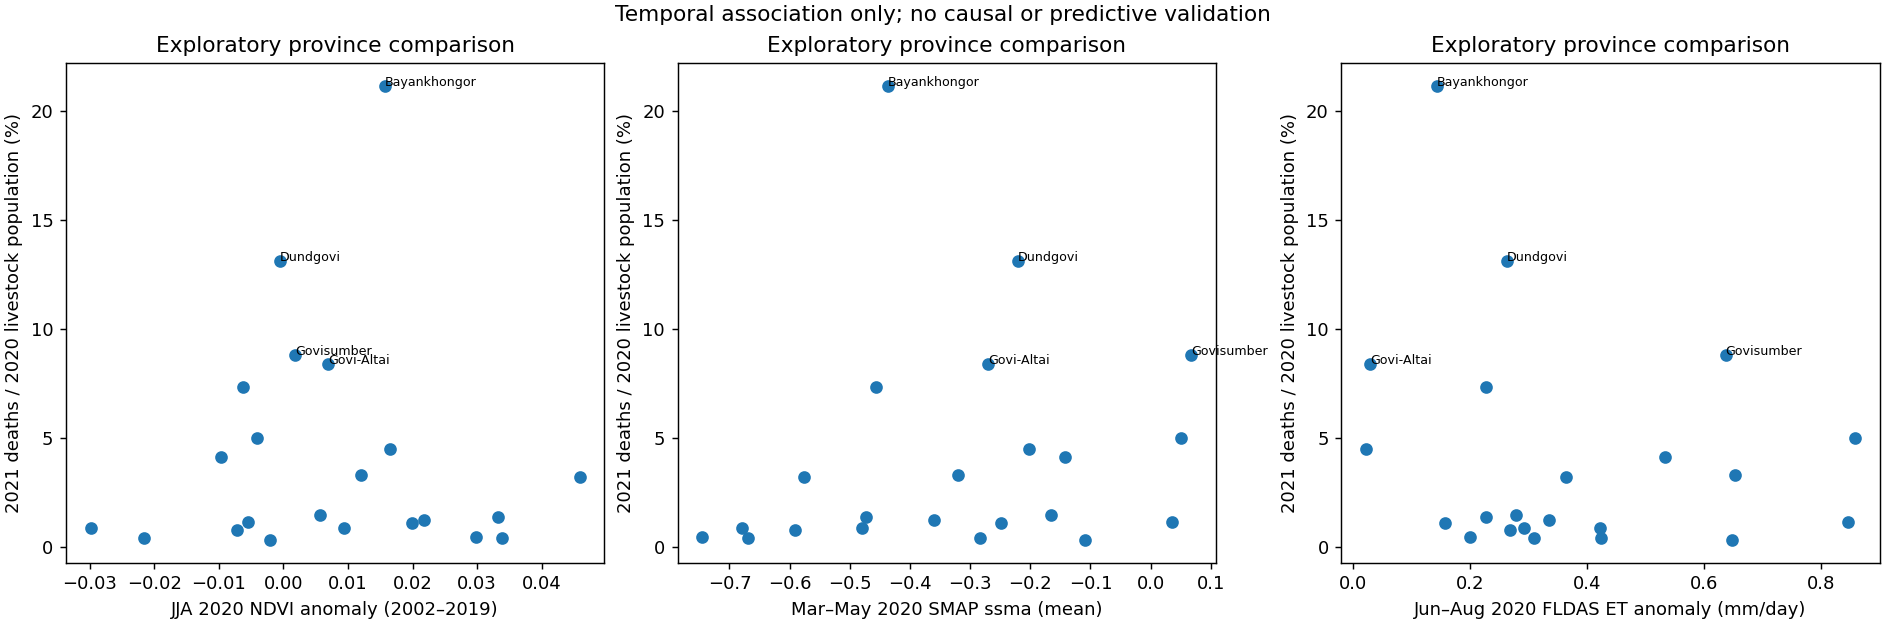

In [3]:
joint,corr=compute_joint_indicators()
print('Matched provinces:',len(joint))
display(corr.round(3))
display(Image(filename=str(RESULTS/'06_exploratory_satellite_mortality_province_scatter.png'),width=1050))

## Sensitivity to missing satellite observations
SMAP has substantial missing export coverage in some southern/western provinces. Recalculate the exploratory Spearman correlations after excluding provinces with less than 75% or 90% coverage.

In [4]:
coverage=pd.read_csv(RESULTS/'coverage_sensitivity_exploratory_correlations.csv')
display(coverage.pivot(index='metric',columns='smap_min_valid_fraction_threshold',values='spearman_rho_exploratory').round(3))

smap_min_valid_fraction_threshold,0.00,0.75,0.90
metric,,,
fldas_et_anomaly_spring_mm_day,-0.455,-0.563,-0.565
fldas_et_anomaly_summer_mm_day,-0.212,0.091,0.047
ndvi_2020_JJA,-0.513,-0.325,-0.468
ndvi_difference_2020_minus_2019,-0.383,-0.247,-0.232
ndvi_true_anomaly_jja_2020,0.001,-0.033,0.121
smap_ssma_spring_mean,0.383,0.442,0.515
smap_ssma_summer_mean,-0.366,-0.149,-0.097


## Scientific interpretation
No p-values, forecasting accuracy or causality are claimed here. Province-level observations are spatially dependent and the 2020–2021 lag alone does not establish mechanisms. The original slides remain a historical research record, not a set of independently verified conclusions.